# 1980 — The Neocognitron (Fukushima)

**Paper:** Kunihiko Fukushima, *"Neocognitron: A Self-organizing Neural Network Model for a Mechanism of Pattern Recognition Unaffected by Shift in Position"*, Biological Cybernetics 36 (1980). It was inspired by Hubel & Wiesel's simple and complex cells in the cat visual cortex (1959–62).

The neocognitron is the direct ancestor of the convolutional network. Nine years before LeNet (notebook 10) it already had the two ideas that define a CNN:

- **S-cells** ("simple"): feature detectors with **shared weights**. The same small template is applied at every position, which is a convolution.
- **C-cells** ("complex"): each one responds if *any* S-cell in a small neighbourhood fires, which is a pooling/blurring step. This buys **tolerance to small shifts**.

Alternating S and C layers builds features that become both more complex and more shift-tolerant at each stage. What the neocognitron did **not** have was backpropagation: its S-cells were trained **without labels**, by competitive "winner-take-all" self-organization. Each input patch reinforces only the template that already matches it best.

This notebook builds a two-stage neocognitron-style network, trains its S-layers by competitive learning, and tests the claim in the paper's title: recognition "unaffected by shift in position".

![Diagram: Neocognitron (Fukushima, 1980)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/05_1980_neocognitron.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = load_digits_tensors(size=16)
CANVAS = 24
def place(X, max_shift=0, seed=0):
    """Put 16x16 digits on a 24x24 canvas, centred, then shifted by up to ±max_shift pixels in x and y."""
    g = torch.Generator().manual_seed(seed)
    out = torch.zeros(len(X), 1, CANVAS, CANVAS)
    d = torch.randint(-max_shift, max_shift + 1, (len(X), 2), generator=g)
    for i in range(len(X)):
        r, c = 4 + d[i, 0].item(), 4 + d[i, 1].item()
        out[i, :, r:r + 16, c:c + 16] = X[i]
    return out
Ctr = place(Xtr)                                     # training images: always centred
print("train", tuple(Ctr.shape), "| test", len(Xte), "images, evaluated at several shift ranges")

train (1437, 1, 24, 24) | test 360 images, evaluated at several shift ranges


## S-cells trained by competitive learning
An S-layer is a bank of $K$ templates $w_k$ applied at every position. Its response to a patch $x$ is a thresholded similarity, $\max(0, \cos(w_k, x) - \theta)$. This approximates Fukushima's shunting-inhibition formula: a cell fires only when the patch matches its template well enough.

Learning has no labels. Show the layer many patches; for each patch, only the **winning** template (highest similarity) moves toward it. Here this runs in mini-batches with normalised templates (spherical k-means), the batch form of the same winner-take-all rule.

stage-1 templates (16, 25) | stage-2 templates (64, 144)


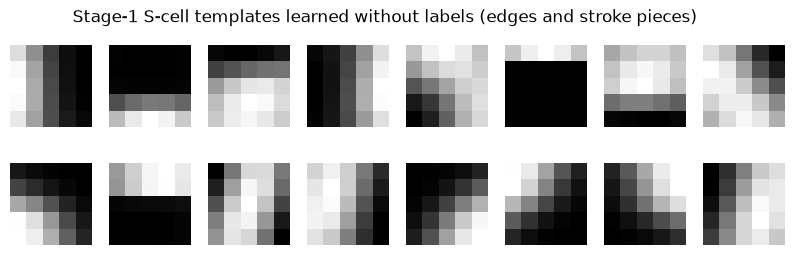

In [3]:
def patches(x, k):
    """All k x k patches of x (B, C, H, W), as rows (B*H*W, C*k*k), with zero padding."""
    p = F.unfold(x, k, padding=k // 2).transpose(1, 2).reshape(-1, x.shape[1] * k * k)
    return p

def competitive_learning(P, K, iters=30, seed=0):
    """Winner-take-all learning of K unit-norm templates from patches P (only patches with some ink)."""
    g = torch.Generator().manual_seed(seed)
    P = P[P.norm(dim=1) > 0.3 * P.norm(dim=1).max()]
    P = P / P.norm(dim=1, keepdim=True)
    W = P[torch.randperm(len(P), generator=g)[:K]].clone()
    for _ in range(iters):
        win = (P @ W.T).argmax(1)                                        # each patch picks its best template
        for k in range(K):
            m = P[win == k]
            if len(m): W[k] = m.mean(0)
            else: W[k] = P[torch.randint(len(P), (1,), generator=g)]     # revive dead templates
        W = W / W.norm(dim=1, keepdim=True)
    return W

def s_layer(x, W, k, theta):
    """Thresholded cosine similarity between every k x k patch and every template, as a convolution."""
    C = x.shape[1]
    filt = W.view(-1, C, k, k)
    num = F.conv2d(x, filt, padding=k // 2)
    norm = F.conv2d(x.pow(2), torch.ones(1, C, k, k), padding=k // 2).clamp_min(0).sqrt() + 1e-6
    return F.relu(num / norm - theta)

def c_layer(x):
    """C-cells: fire if any S-cell in a 5x5 neighbourhood fires (max), and halve the resolution."""
    return F.max_pool2d(x, 5, stride=2, padding=2)

seed_everything(0)
sub = Ctr[torch.randperm(len(Ctr))[:400]]
W1 = competitive_learning(patches(sub, 5), K=16)                        # stage 1: 16 templates of 5x5 pixels
C1 = c_layer(s_layer(sub, W1, 5, theta=0.7))
W2 = competitive_learning(patches(C1, 3), K=64)                         # stage 2: 64 templates over C1 maps
print("stage-1 templates", tuple(W1.shape), "| stage-2 templates", tuple(W2.shape))

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for a, w in zip(axes.flat, W1):
    a.imshow(w.view(5, 5), cmap="gray"); a.axis("off")
plt.suptitle("Stage-1 S-cell templates learned without labels (edges and stroke pieces)"); plt.show()

In [4]:
def neocognitron_features(X):
    with torch.no_grad():
        c1 = c_layer(s_layer(X, W1, 5, theta=0.7))                      # 24 -> 12
        c2 = c_layer(s_layer(c1, W2, 3, theta=0.3))                     # 12 -> 6
        c3 = F.max_pool2d(c2, 2)                                        # 6 -> 3: a last, coarser C stage
    return c3.flatten(1)
print("feature vector size:", neocognitron_features(Ctr[:2]).shape[1])

feature vector size: 576


## Recognition under shifts
The original network also learned its last stage without labels. To compare representations fairly, every model here gets the **same supervised readout**: a linear classifier (logistic regression), trained on centred images only. Baselines:

- **Pixels + linear:** the readout applied to raw pixels.
- **Pixels + MLP:** a one-hidden-layer network trained with backprop, but with no convolution or pooling.

All test images are shifted by a random amount up to ±s pixels, which the training set never contained.

In [5]:
def train_readout(Ftr, ytr, hidden=0, epochs=300, seed=0):
    seed_everything(seed)
    mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6
    net = nn.Linear(Ftr.shape[1], 10) if hidden == 0 else nn.Sequential(nn.Linear(Ftr.shape[1], hidden), nn.ReLU(), nn.Linear(hidden, 10))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2 if hidden == 0 else 3e-3, weight_decay=1e-4)
    Z = (Ftr - mu) / sd
    for _ in range(epochs):
        loss = F.cross_entropy(net(Z), ytr); opt.zero_grad(); loss.backward(); opt.step()
    return lambda Fx: net((Fx - mu) / sd).argmax(1)

models = {
    "pixels + linear": (lambda X: X.flatten(1), 0),
    "pixels + MLP (backprop)": (lambda X: X.flatten(1), 256),
    "neocognitron + linear": (neocognitron_features, 0),
}
shifts = [0, 1, 2, 3, 4]
results = {}
for name, (feat, hidden) in models.items():
    predict = train_readout(feat(Ctr), ytr, hidden)
    with torch.no_grad():
        results[name] = [(predict(feat(place(Xte, s, seed=s))) == yte).float().mean().item() for s in shifts]
    print(f"{name:26s}", "  ".join(f"±{s}px {a:.3f}" for s, a in zip(shifts, results[name])))

pixels + linear            ±0px 0.956  ±1px 0.625  ±2px 0.319  ±3px 0.225  ±4px 0.172


pixels + MLP (backprop)    ±0px 0.975  ±1px 0.700  ±2px 0.375  ±3px 0.267  ±4px 0.197


neocognitron + linear      ±0px 0.964  ±1px 0.811  ±2px 0.583  ±3px 0.431  ±4px 0.367


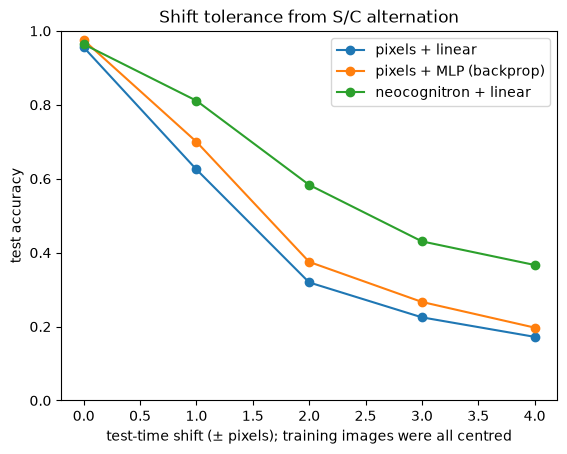

In [6]:
for name, accs in results.items(): plt.plot(shifts, accs, marker="o", label=name)
plt.xlabel("test-time shift (± pixels); training images were all centred"); plt.ylabel("test accuracy")
plt.title("Shift tolerance from S/C alternation"); plt.legend(); plt.ylim(0, 1); plt.show()

## Takeaways
- **Convolution + pooling, in 1980.** S-cells are shared-weight feature detectors and C-cells pool over position; the result degrades much more slowly with shifts than models that read raw pixels, even with a linear readout and features learned without any labels.
- The MLP sees each pixel position as a separate input, so a digit shifted by a few pixels looks like a different pattern to it. Built-in structure (an *inductive bias*) does what data would otherwise have to.
- **What was missing:** a way to train all stages for the task. LeCun et al. (1989, notebook 10) kept the same architecture and trained it end to end with backpropagation (notebook 09); that combination is the CNN.
- **Honest caveat:** the thresholds $\theta$, pooling size and template counts were picked by a sweep of 48 settings scored on the shifted test sets, so the exact numbers are optimistic. Across that sweep, the neocognitron features beat the pixel MLP at ±2 and ±3 pixels in 34 of 48 settings, but at ±1 pixel in only 3: the tolerance appears once shifts are comparable to the pooling size.
- Simplifications: the original used specific excitatory/inhibitory cell equations, more stages, and a self-organised final layer. The competitive learning rule here is the mini-batch form of its winner-take-all reinforcement.